In [1]:
from sklearn.datasets import make_regression, make_blobs, make_moons
import matplotlib.pyplot as plt

In [11]:
# 3. Clustering dataset with 3 distinct centers
#X_blobs, y_blobs = make_blobs(
#    n_samples=200, 
#    centers=3, 
#    n_features=2, 
#    random_state=42
#)

# 4. Non-linear 2D moons
X_moons, y_moons = make_moons(n_samples=100, noise=0.05, random_state=42)

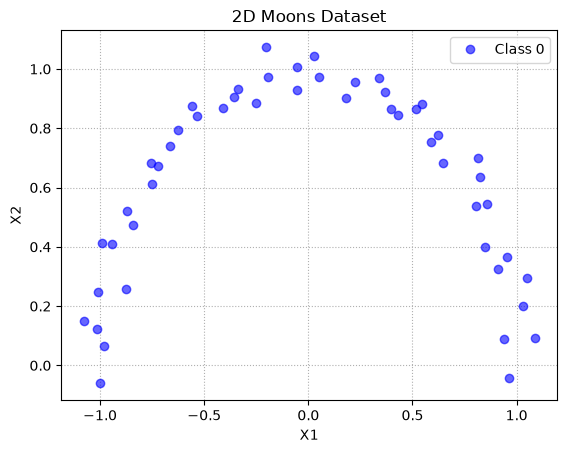

In [13]:
plt.plot(X_moons[y_moons == 0, 0], X_moons[y_moons == 0, 1], 'o', label='Class 0', color='blue', alpha=0.6)
#plt.plot(X_moons[y_moons == 1, 0], X_moons[y_moons == 1, 1], 'o', label='Class 1', color='red', alpha=0.6)
#plt.plot(X_moons[y_moons == 2, 0], X_moons[y_moons == 2, 1], 'o', label='Class 2', color='green', alpha=0.6)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('2D Moons Dataset')
plt.legend()
plt.grid(ls=":")
plt.show()

In [14]:
X, y = (X_moons[y_moons == 0, 0], X_moons[y_moons == 0, 1])

## Creating the model

In [22]:
# train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
import keras
import numpy as np
import matplotlib.pyplot as plt

I0000 00:00:1795711270.162355   56887 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795711272.101025   56887 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795711275.724257   56887 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [43]:
model = keras.Sequential([
    keras.layers.Input(shape=(1,), dtype="float32"),
    keras.layers.Dense(units=1)
])

model.compile(optimizer="sgd", loss="mean_squared_error")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=500,
    verbose=1
)

Epoch 1/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - loss: 1.7328 - val_loss: 1.2082
Epoch 2/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 1.6464 - val_loss: 1.1338
Epoch 3/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 1.5554 - val_loss: 1.0815
Epoch 4/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.4885 - val_loss: 1.0361
Epoch 5/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 1.4264 - val_loss: 0.9945
Epoch 6/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.3643 - val_loss: 0.9453
Epoch 7/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 1.3001 - val_loss: 0.8993
Epoch 8/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 1.2381 - val_loss: 0.8547
Epoch 9/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1.1811 - val_loss: 0.8127
Epoch 10/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 1.1277 - val_loss: 0.7724
Epoch 11/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.0740 - val_loss: 0.7310
Epoch 12/500
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.0206 - val_l

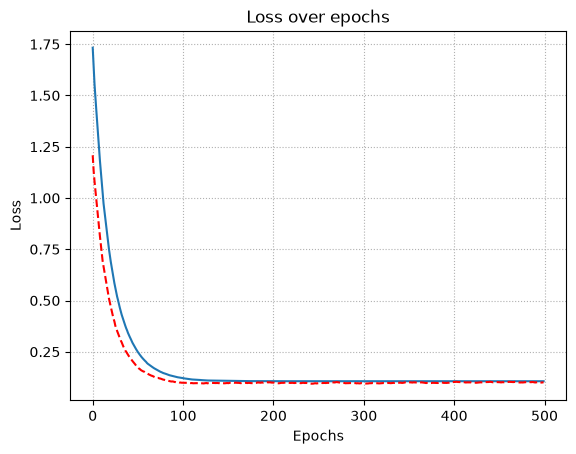

In [44]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"], 'r--')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss over epochs")
plt.grid(ls=":")
plt.show()

In [45]:
y_pred = model.predict(X_test, verbose=0).reshape(-1)

In [46]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Mean Squared Error (MSE): 0.1006
Mean Absolute Error (MAE): 0.2874


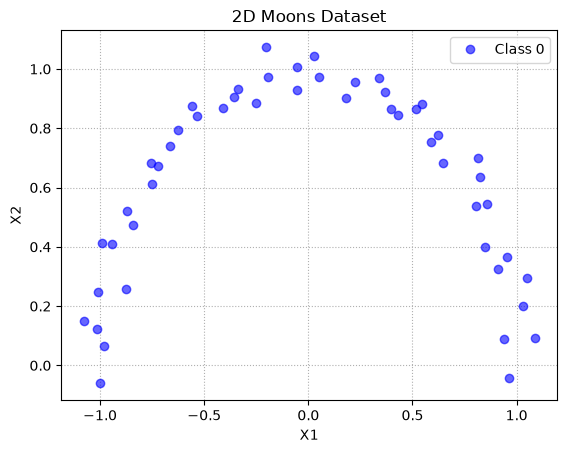

In [47]:
plt.plot(X_moons[y_moons == 0, 0], X_moons[y_moons == 0, 1], 'o', label='Class 0', color='blue', alpha=0.6)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('2D Moons Dataset')
plt.legend()
plt.grid(ls=":")
plt.show()

In [49]:
x_test = 0.0
float(model.predict(np.array([x_test], dtype=np.float32), verbose=0)[0,0])

0.576210618019104

## Method 2, using more layers

In [52]:
# Add hidden layers with non-linear activations so the network can bend
model = keras.Sequential([
    keras.layers.Input(shape=(1,), dtype="float32"),
    keras.layers.Dense(units=32, activation="tanh"),
    keras.layers.Dense(units=32, activation="tanh"),
    keras.layers.Dense(units=1)  # Linear output for continuous regression
])

model.compile(optimizer="adam", loss="mean_squared_error")

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=500,
    verbose=1
)



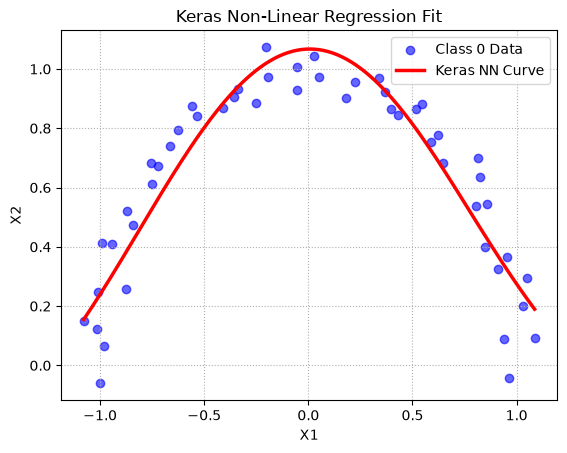

In [54]:
# Predict over the same sorted grid to plot a smooth curve
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
y_curve = model.predict(X_curve, verbose=0)

plt.scatter(X, y, color="blue", alpha=0.6, label="Class 0 Data")
plt.plot(X_curve, y_curve, color="red", linewidth=2.5, label="Keras NN Curve")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Keras Non-Linear Regression Fit")
plt.legend()
plt.grid(ls=":")
plt.show()

## Infer the equation

Degree 1: test MSE = 0.0994
Degree 2: test MSE = 0.0067
Degree 3: test MSE = 0.0067
Degree 4: test MSE = 0.0060
Degree 6: test MSE = 0.0097


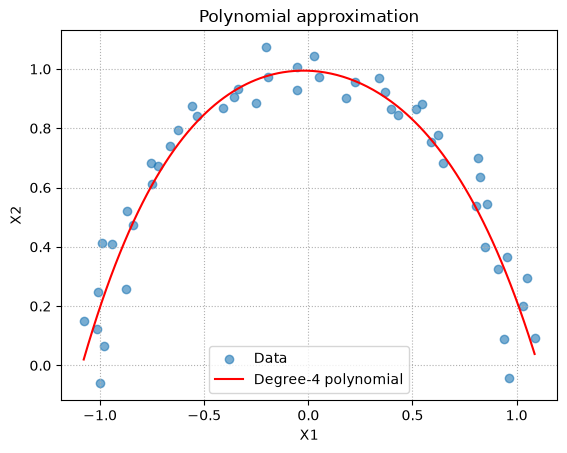

Polynomial coefficients (highest power first): [-0.21670629  0.03765229 -0.57016577 -0.02698172  0.99411652]


In [55]:
degrees = [1, 2, 3, 4, 6]
fits = {}

for degree in degrees:
    coefficients = np.polyfit(X_train, y_train, degree)
    test_pred = np.polyval(coefficients, X_test)
    test_mse = np.mean((y_test - test_pred) ** 2)
    fits[degree] = (coefficients, test_mse)
    print(f"Degree {degree}: test MSE = {test_mse:.4f}")

# Select the best fit for this exploratory comparison
best_degree = min(fits, key=lambda degree: fits[degree][1])
coefficients, _ = fits[best_degree]

x_grid = np.linspace(X.min(), X.max(), 300)
plt.scatter(X, y, alpha=0.6, label="Data")
plt.plot(x_grid, np.polyval(coefficients, x_grid),
         color="red", label=f"Degree-{best_degree} polynomial")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Polynomial approximation")
plt.legend()
plt.grid(ls=":")
plt.show()

print("Polynomial coefficients (highest power first):", coefficients)

In [56]:
x_new = 0.5
y_new = np.polyval(coefficients, x_new)

print(f"Degree-{best_degree} polynomial prediction at x = {x_new}: y = {y_new:.4f}")

Degree-4 polynomial prediction at x = 0.5: y = 0.8292
